Cross-region screening and geographic replication

Compare five development Earth regions under the predeclared
screening comparison described below. The saved baseline masks are
unchanged. Two alternative policies are diagnostic, with the same source-support
and built/crop/permanent-water exclusions. No model or final-reserve morphology
is used. WorldCover classes are source labels, not independent land-cover truth.

In [1]:
import hashlib
import json
import sys
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import rasterio
from IPython.display import Image, Markdown, display
from matplotlib.cm import ScalarMappable
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.figure import Figure
from rasterio.warp import transform as project_points
from rasterio.warp import transform_bounds
from rasterio.windows import Window, from_bounds

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'outline.md').exists())
sys.path.insert(0, str(ROOT))
from notebooks.shared.inspection import check_input, file_hash, verify_run
from notebooks.shared.patch_analysis import measure_patch, measure_planarity
from notebooks.shared.retrieval_analysis import terrain_discrepancies
from notebooks.exploration.screening_analysis import screen_patch

NOTEBOOK = ROOT / 'notebooks/exploration/22_cross_region_screening_eda.ipynb'
PREVIOUS = ROOT / 'data/processed/analysis/scale-eda-20261029T012946475712Z'
DEATH_EDA = ROOT / 'data/processed/analysis/death-valley-eda-20261029T080731329448Z'
RUN_PATHS = {
    'original': 'data/processed/earth_terrain_landcover/20261028T063142045472Z_9d6d3b',
    'death_valley': 'data/processed/earth_terrain_expansion/20261029T075850772998Z_b58cb9',
    'wadi_rum': 'data/processed/earth_terrain_expansion/20261029T084504362605Z_6b826e',
}
SITES = ['atacama_san_pedro', 'lanzarote', 'northern_arizona', 'death_valley', 'wadi_rum']
SIZES = [300, 600, 960]
POLICIES = ['baseline', 'patch_mean_bare80', 'no_bare_requirement']
SCENARIOS = ['baseline', 'with_planarity']
FEATURES = ['slope_median_deg', 'slope_p90_deg', 'central_relief_m', 'plane_residual_fraction', 'local_sd_median_m']
CHANNELS = ['elevation_m', 'relative_elevation_m', 'slope_deg', 'laplacian_per_m', 'local_elevation_std_m']
COVER_FIELDS = ['source_coverage', 'bare_sparse_fraction', 'built_fraction', 'crop_fraction', 'water_fraction']
OUT = ROOT / 'data/processed/analysis' / ('screening-eda-' + datetime.now(UTC).strftime('%Y%m%dT%H%M%S%fZ'))
OUT.mkdir(parents=True, exist_ok=False)
expected: dict[str, str] = {}
evidence: dict[str, str] = {}
SOURCE_NOTE = ROOT / 'data/reference/screening-policy-20261029/SOURCE_INTERPRETATION.md'
evidence[str(SOURCE_NOTE)] = file_hash(SOURCE_NOTE)
runs = {name: ROOT / path for name, path in RUN_PATHS.items()}
run_records = {}
for name, run in runs.items():
    expected.update(verify_run(run))
    record = json.loads((run / 'provenance.json').read_text())
    run_records[name] = record
    expected.update({str((ROOT / path).resolve()): item['sha256'] for path, item in record['inputs'].items()})
    evidence[str(run / 'provenance.json')] = file_hash(run / 'provenance.json')
for previous in [PREVIOUS, DEATH_EDA]:
    record = json.loads((previous / 'provenance.json').read_text())
    assert record['status'] == 'complete'
    expected.update({str((previous / name).resolve()): value for name, value in record['outputs'].items()})
    evidence[str(previous / 'provenance.json')] = file_hash(previous / 'provenance.json')
old_metrics = pd.read_csv(check_input(PREVIOUS / 'center_metrics.csv', expected, evidence))
death_metrics = pd.read_csv(check_input(DEATH_EDA / 'new_center_metrics.csv', expected, evidence))
old_baseline = pd.concat([old_metrics.loc[old_metrics['body'] == 'earth'], death_metrics], ignore_index=True)
queries = old_metrics.loc[(old_metrics['body'] == 'moon') & old_metrics['common']].copy()
source = '\n'.join(c.source for c in nbformat.read(NOTEBOOK, as_version=4).cells)
provenance: dict[str, Any] = {
    'status': 'running', 'notebook': str(NOTEBOOK.relative_to(ROOT)),
    'notebook_source_sha256': hashlib.sha256(source.encode()).hexdigest(), 'runs': RUN_PATHS,
    'helpers': {name: file_hash(ROOT / 'notebooks' / name) for name in
                ['shared/inspection.py', 'shared/patch_analysis.py', 'shared/retrieval_analysis.py', 'exploration/screening_analysis.py']},
    'sites': SITES, 'sizes_m': SIZES, 'policies': POLICIES, 'scenarios': SCENARIOS,
    'role': 'development only', 'cohorts': ['eligible_at_size', 'common_all_sizes'],
    'center_lattice': 'origin16/stride32cells; largest window fits array',
    'queries': 'fixed notebook16 common960 lunar centers; separate support views',
    'policy_status': 'diagnostic alternatives; processed masks unchanged',
    'software': {p: version(p) for p in ['numpy', 'pandas', 'rasterio', 'matplotlib', 'nbformat']},
}
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')


def save_figure(fig: Figure, name: str) -> None:
    fig.savefig(OUT / f'{name}.png', bbox_inches='tight')
    fig.savefig(OUT / f'{name}.pdf', bbox_inches='tight')
    display(Image(filename=str(OUT / f'{name}.png')))
    plt.close(fig)


def read_native_classes(path: Path, bounds: tuple[float, float, float, float], crs: Any) -> tuple[np.ndarray, np.ndarray, list[float]]:
    """Read native class pixels whose centers fall inside the projected patch."""
    with rasterio.open(check_input(path, expected, evidence)) as src:
        geographic = transform_bounds(crs, src.crs, *bounds, densify_pts=21)
        fractional = from_bounds(*geographic, transform=src.transform)
        left, top = int(np.floor(fractional.col_off)), int(np.floor(fractional.row_off))
        right = int(np.ceil(fractional.col_off + fractional.width))
        bottom = int(np.ceil(fractional.row_off + fractional.height))
        window = Window.from_slices((top, bottom), (left, right), boundless=True)
        raw = src.read(1, window=window, boundless=True, fill_value=0)
        transform = src.window_transform(window)
        rr, cc = np.indices(raw.shape)
        x = transform.c + (cc + .5) * transform.a
        y = transform.f + (rr + .5) * transform.e
        projected = project_points(src.crs, crs, x.ravel().tolist(), y.ravel().tolist())
        px, py = projected[0], projected[1]
        selected = ((np.array(px) >= bounds[0]) & (np.array(px) < bounds[2])
                    & (np.array(py) >= bounds[1]) & (np.array(py) < bounds[3])).reshape(raw.shape)
        extent = [transform.c, transform.c + raw.shape[1] * transform.a,
                  transform.f + raw.shape[0] * transform.e, transform.f]
        return raw, selected, extent


print('Output:', OUT)

Output: .\data\processed\analysis\screening-eda-20261102T150311044638Z


# Same lattice, three policy flags, no change to source masks

A record is a complete-terrain center/size window. Unknown land-cover support
is retained in diagnostics but cannot qualify under any policy. Candidate
membership always requires complete support across the window. Patch-mean
eligibility need not be monotonic with scale; common membership is the explicit
intersection across 300, 600 and 960 m. Site-local projected coordinates are saved.

In [2]:
records: list[dict[str, Any]] = []
grids: dict[str, Any] = {}
folders: dict[str, Path] = {}
native_paths: dict[str, Path] = {}
for site in SITES:
    stage = site if site in runs else 'original'
    run = runs[stage]
    folder = run / 'earth' / site / 'grid_30m'
    folders[site] = folder
    layers = {}
    grid = None
    for channel in [*CHANNELS, *COVER_FIELDS, 'natural_screen_mask']:
        with rasterio.open(check_input(folder / f'{channel}.tif', expected, evidence)) as src:
            current = (src.shape, src.transform, src.crs)
            assert grid is None or current == grid
            grid = current
            layers[channel] = src.read(1, masked=True).astype('float32').filled(np.nan)
    assert grid is not None
    shape, transform, crs = grid
    assert crs is not None and transform.a == 30 and transform.e == -30
    grids[site] = {'shape': shape, 'transform': list(transform), 'crs_wkt': crs.to_wkt(),
                   'folder': str(folder.relative_to(ROOT)), 'bbox': run_records[stage]['config']['areas'][site]['bbox']}
    complete = np.logical_and.reduce([np.isfinite(layers[c]) for c in CHANNELS])
    for center_row in range(16, shape[0] - 15, 32):
        for center_col in range(16, shape[1] - 15, 32):
            for size in SIZES:
                half = size // 60
                row, col = center_row - half, center_col - half
                window = np.s_[row:row + 2 * half, col:col + 2 * half]
                if not complete[window].all():
                    continue
                flags = screen_patch(*[layers[c][window] for c in COVER_FIELDS])
                assert flags['baseline'] == bool((layers['natural_screen_mask'][window] == 1).all())
                x, y = transform * (center_col, center_row)
                records.append({'region': site, 'size_m': size, 'center_row': center_row, 'center_col': center_col,
                                'row': row, 'col': col, 'center_x_m': x, 'center_y_m': y,
                                'center_id': f'{site}:natural_screen:{center_row}:{center_col}',
                                **flags, **measure_patch(layers['elevation_m'][window], layers['slope_deg'][window],
                                                        layers['local_elevation_std_m'][window]),
                                **measure_planarity(layers['elevation_m'][window])})
    if stage != 'original':
        native_paths[site] = run / 'earth' / site / 'worldcover_native_mosaic.tif'
    else:
        tile_id = {'atacama_san_pedro': 'S24W069', 'lanzarote': 'N27W015', 'northern_arizona': 'N33W114'}[site]
        native_paths[site] = ROOT / f'data/raw/earth/worldcover/v200/2021/map/ESA_WorldCover_10m_2021_v200_{tile_id}_Map.tif'
    del layers, complete
    print(site, 'recorded')
patches = pd.DataFrame(records)
assert not patches.duplicated(['center_id', 'size_m']).any()
assert np.isfinite(patches[FEATURES]).all().all()
for policy in POLICIES:
    passes = patches.groupby('center_id')[policy].transform('sum')
    patches[f'{policy}_common'] = (passes == 3) & (patches.groupby('center_id')['size_m'].transform('size') == 3)
assert (patches['baseline'] <= patches['patch_mean_bare80']).all()
assert (patches['patch_mean_bare80'] <= patches['no_bare_requirement']).all()
for site in SITES[:4]:
    a = patches.loc[(patches['region'] == site) & patches['baseline']].sort_values(['center_id', 'size_m'])
    b = old_baseline.loc[old_baseline['region'] == site].sort_values(['center_id', 'size_m'])
    assert a['center_id'].tolist() == b['center_id'].tolist() and a['size_m'].tolist() == b['size_m'].tolist()
    assert a['baseline_common'].tolist() == b['common'].tolist()
    np.testing.assert_allclose(a[FEATURES].to_numpy(), b[FEATURES].to_numpy(), rtol=1e-8, atol=1e-8)
patches.to_csv(OUT / 'center_screening_metrics.csv.gz', index=False, compression='gzip')
(OUT / 'site_grids.json').write_text(json.dumps(grids, indent=2), encoding='utf-8')

atacama_san_pedro recorded


lanzarote recorded


northern_arizona recorded


death_valley recorded


wadi_rum recorded


5375

# Inventories and distributions

The diagnostic alternatives are nested at a fixed size. Changes in counts and
descriptors can reflect source class distribution and spatial fragmentation.
Numbers of centers do not measure independent sample size. Keep per-site values
visible instead of allowing the largest ROI to dominate a pooled summary.

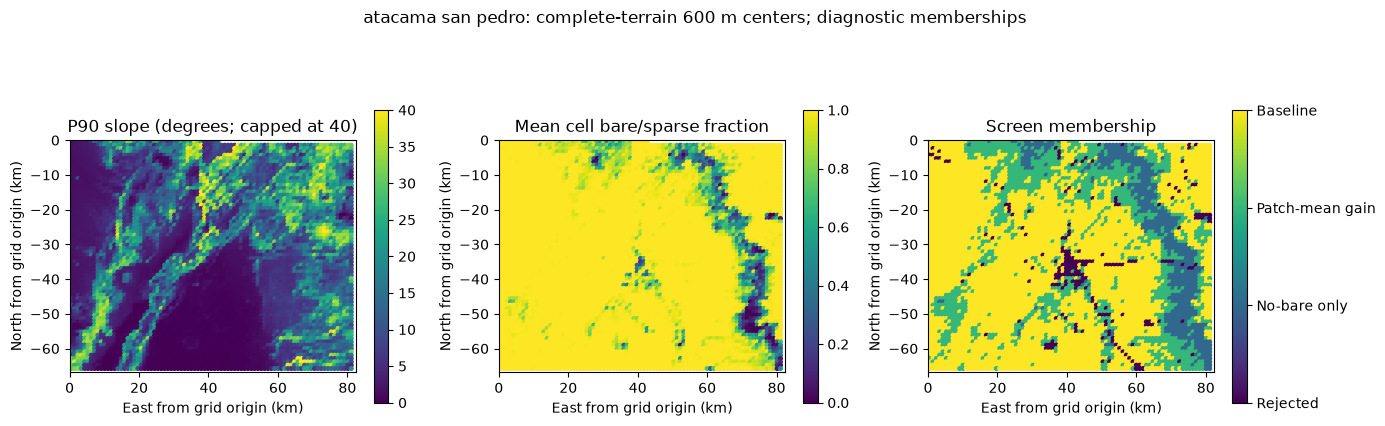

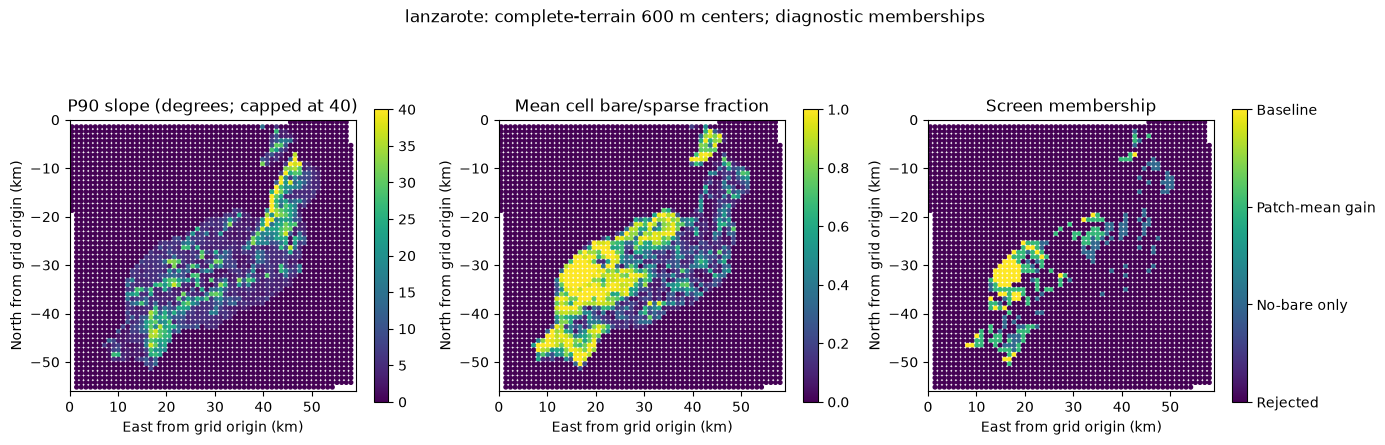

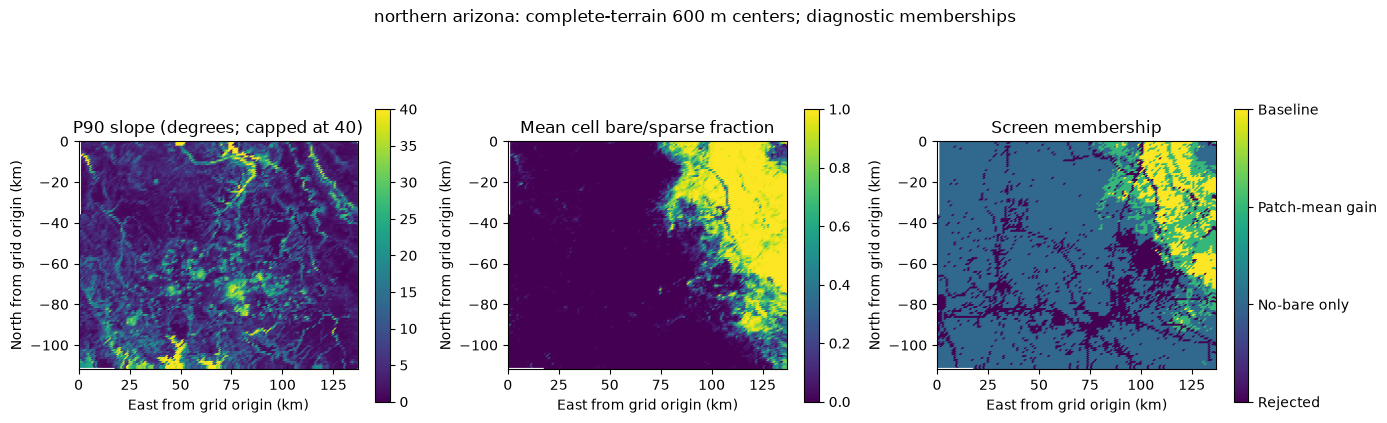

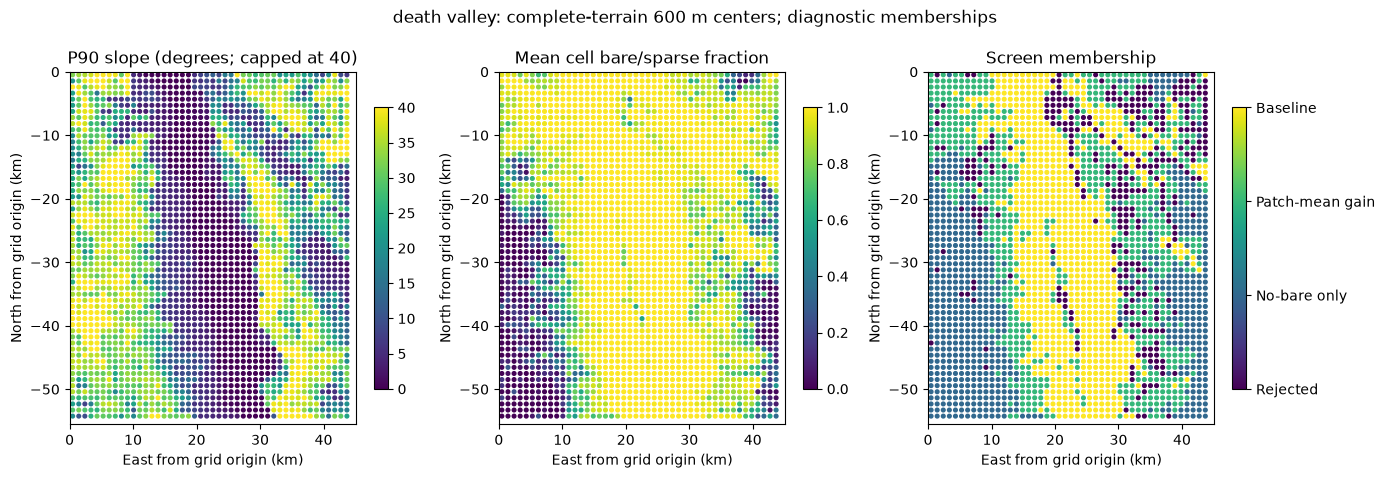

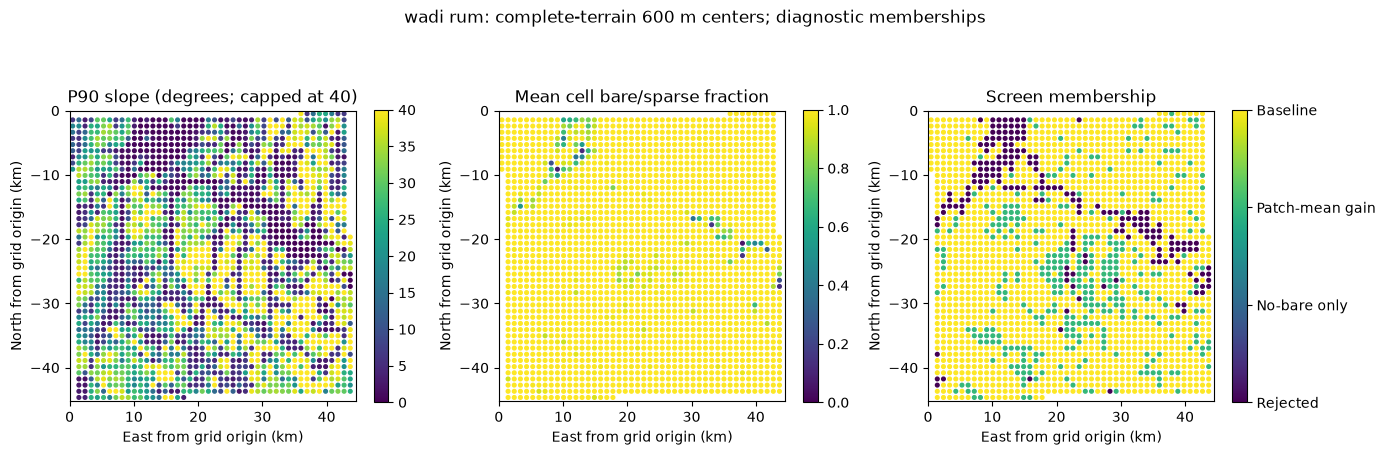

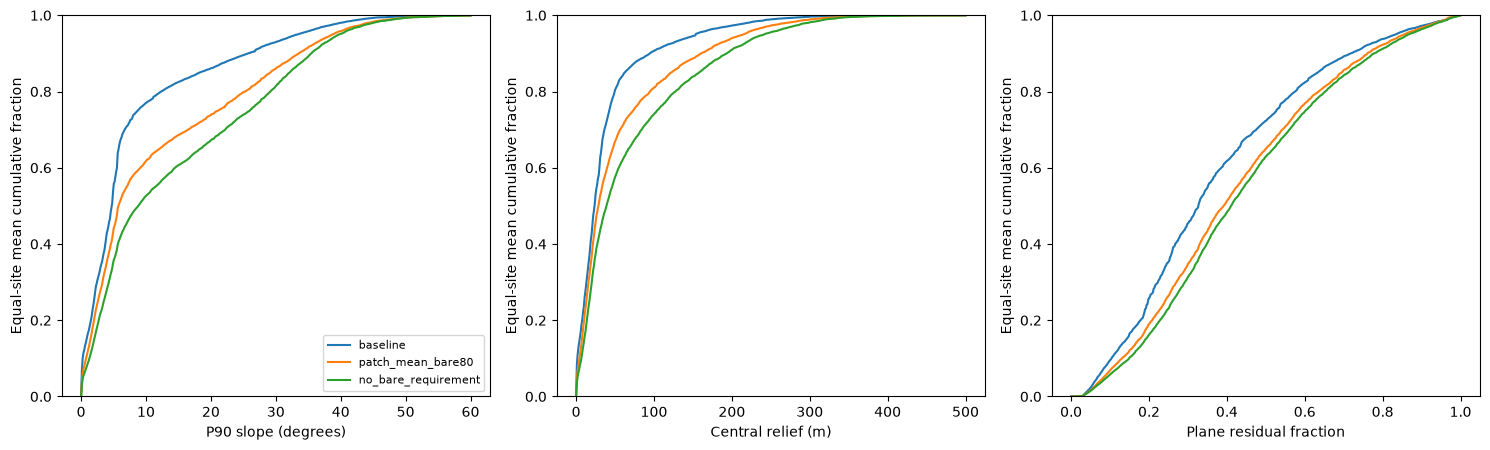

In [3]:
inventory_rows = []
for key, group in patches.groupby(['region', 'size_m']):
    assert isinstance(key, tuple)
    site, size = key
    for cohort in ['eligible_at_size', 'common_all_sizes']:
        for policy in POLICIES:
            flag = policy if cohort == 'eligible_at_size' else f'{policy}_common'
            selected = group.loc[group[flag]]
            inventory_rows.append({'region': site, 'size_m': size, 'cohort': cohort, 'policy': policy,
                                   'terrain_complete_centers': len(group), 'known_landcover_centers': int(group['known_landcover'].sum()),
                                   'hard_exclusion_pass_centers': int(group['hard_exclusions_pass'].sum()),
                                   'centers': len(selected), 'retained_pct': 100 * len(selected) / len(group),
                                   'p90_at_least_15deg_centers': int((selected['slope_p90_deg'] >= 15).sum()),
                                   'slope_p90_median_deg': selected['slope_p90_deg'].median(),
                                   'central_relief_median_m': selected['central_relief_m'].median(),
                                   'plane_fraction_median': selected['plane_residual_fraction'].median()})
inventory = pd.DataFrame(inventory_rows)
inventory.to_csv(OUT / 'policy_inventory.csv', index=False)
failures = patches.groupby(['region', 'size_m'])[['unknown_support_cells', 'bare_failure_cells', 'built_failure_cells',
                                                'crop_failure_cells', 'water_failure_cells']].agg(lambda x: int((x > 0).sum())).reset_index()
failures.to_csv(OUT / 'overlapping_failure_counts.csv', index=False)
for site in SITES:
    group = patches.loc[(patches['region'] == site) & (patches['size_m'] == 600)]
    grid = grids[site]
    origin_x, origin_y = grid['transform'][2], grid['transform'][5]
    x = (group['center_x_m'] - origin_x) / 1000
    y = (group['center_y_m'] - origin_y) / 1000
    category = np.select([group['baseline'], group['patch_mean_bare80'], group['no_bare_requirement']], [3, 2, 1], default=0)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
    for ax, values, title, low, high in zip(axes, [group['slope_p90_deg'], group['bare_mean'], category],
                                            ['P90 slope (degrees; capped at 40)', 'Mean cell bare/sparse fraction', 'Screen membership'],
                                            [0, 0, 0], [40, 1, 3], strict=True):
        im = ax.scatter(x, y, c=values, s=7, vmin=low, vmax=high, cmap='viridis')
        ax.set(title=title, xlabel='East from grid origin (km)', ylabel='North from grid origin (km)', aspect='equal',
               xlim=(0, grid['shape'][1] * .03), ylim=(-grid['shape'][0] * .03, 0))
        bar = fig.colorbar(im, ax=ax, shrink=.7)
        if title == 'Screen membership':
            bar.set_ticks([0, 1, 2, 3], labels=['Rejected', 'No-bare only', 'Patch-mean gain', 'Baseline'])
    fig.suptitle(site.replace('_', ' ') + ': complete-terrain 600 m centers; diagnostic memberships')
    fig.tight_layout()
    save_figure(fig, f'map_{site}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, feature, label in zip(axes, ['slope_p90_deg', 'central_relief_m', 'plane_residual_fraction'],
                               ['P90 slope (degrees)', 'Central relief (m)', 'Plane residual fraction'], strict=True):
    for policy in POLICIES:
        # Equal-weight empirical site CDF, not pooled patch-weighted distribution.
        domain = np.linspace(0, 1 if feature == 'plane_residual_fraction' else 60 if feature == 'slope_p90_deg' else 500, 501)
        curves = []
        for site in SITES:
            values = np.sort(patches.loc[(patches['region'] == site) & (patches['size_m'] == 600) & patches[policy], feature])
            assert len(values) > 0
            curves.append(np.searchsorted(values, domain, side='right') / len(values))
        ax.plot(domain, np.mean(curves, axis=0), label=policy)
    ax.set(xlabel=label, ylabel='Equal-site mean cumulative fraction', ylim=(0, 1))
axes[0].legend(fontsize=8)
fig.tight_layout()
save_figure(fig, '600m_policy_distributions')

# Native class examples selected without lunar scores

At each site, choose one median-P90-slope 600 m example from each nonempty
admission group, ties by row/column. WorldCover native pixel centers are clipped
to the projected patch. Source categories and coordinates are retained. The
maps cannot establish current cover, source correctness or operational readiness.

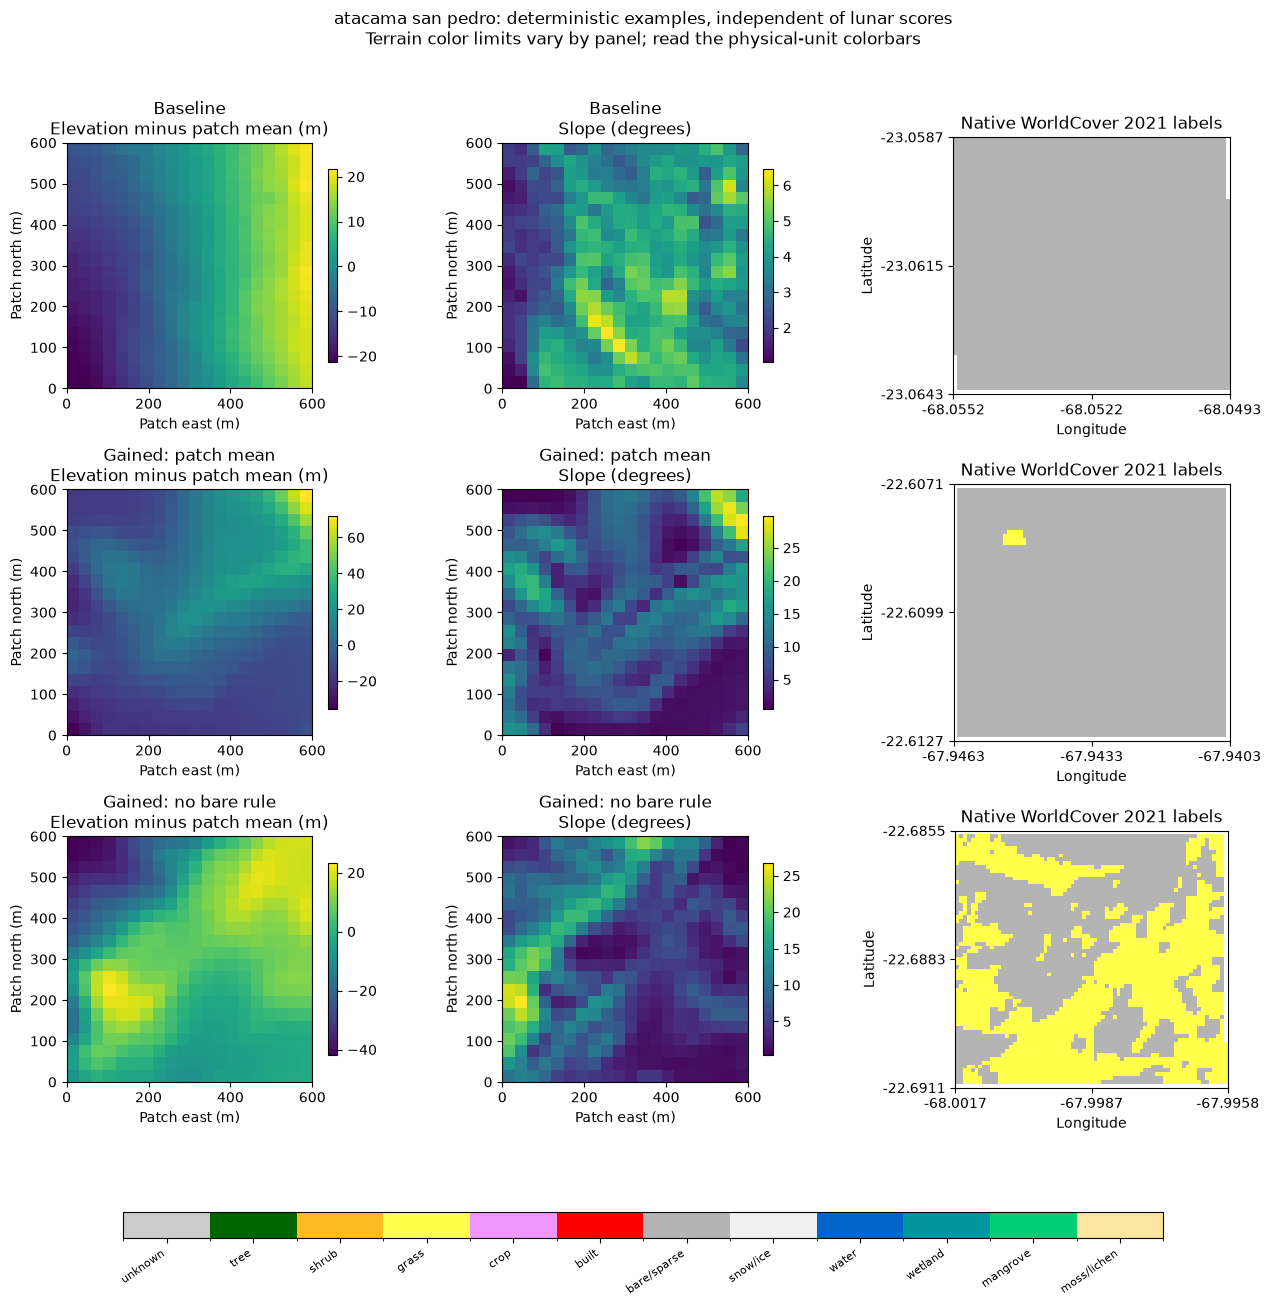

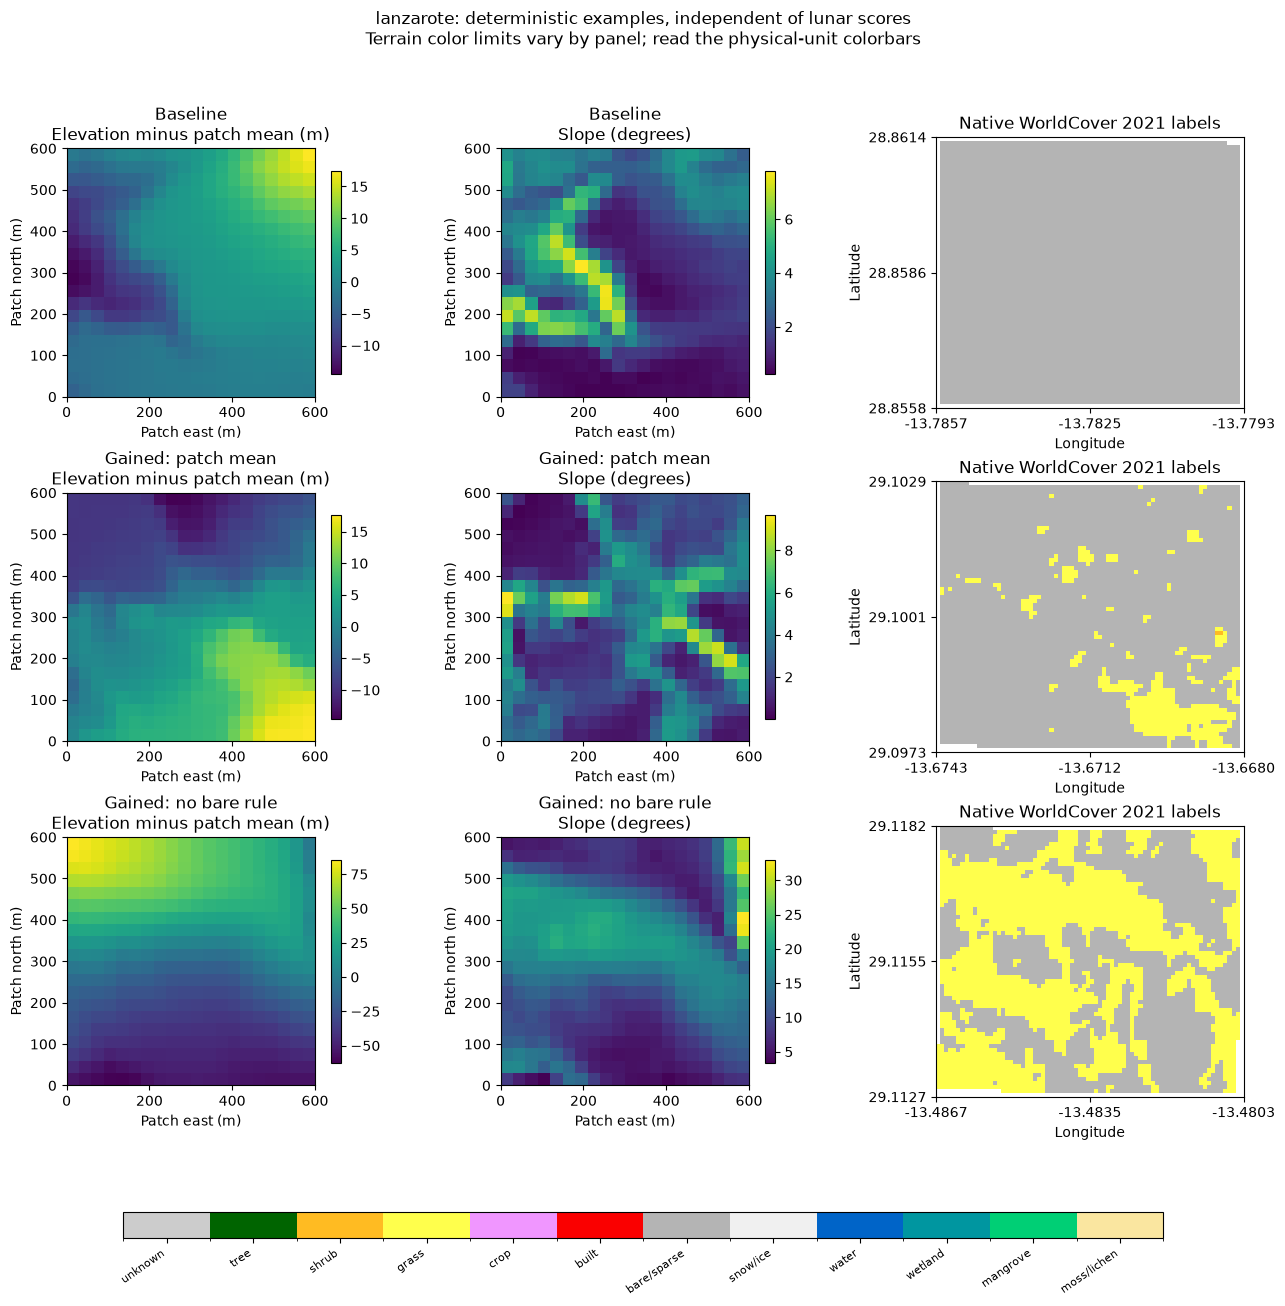

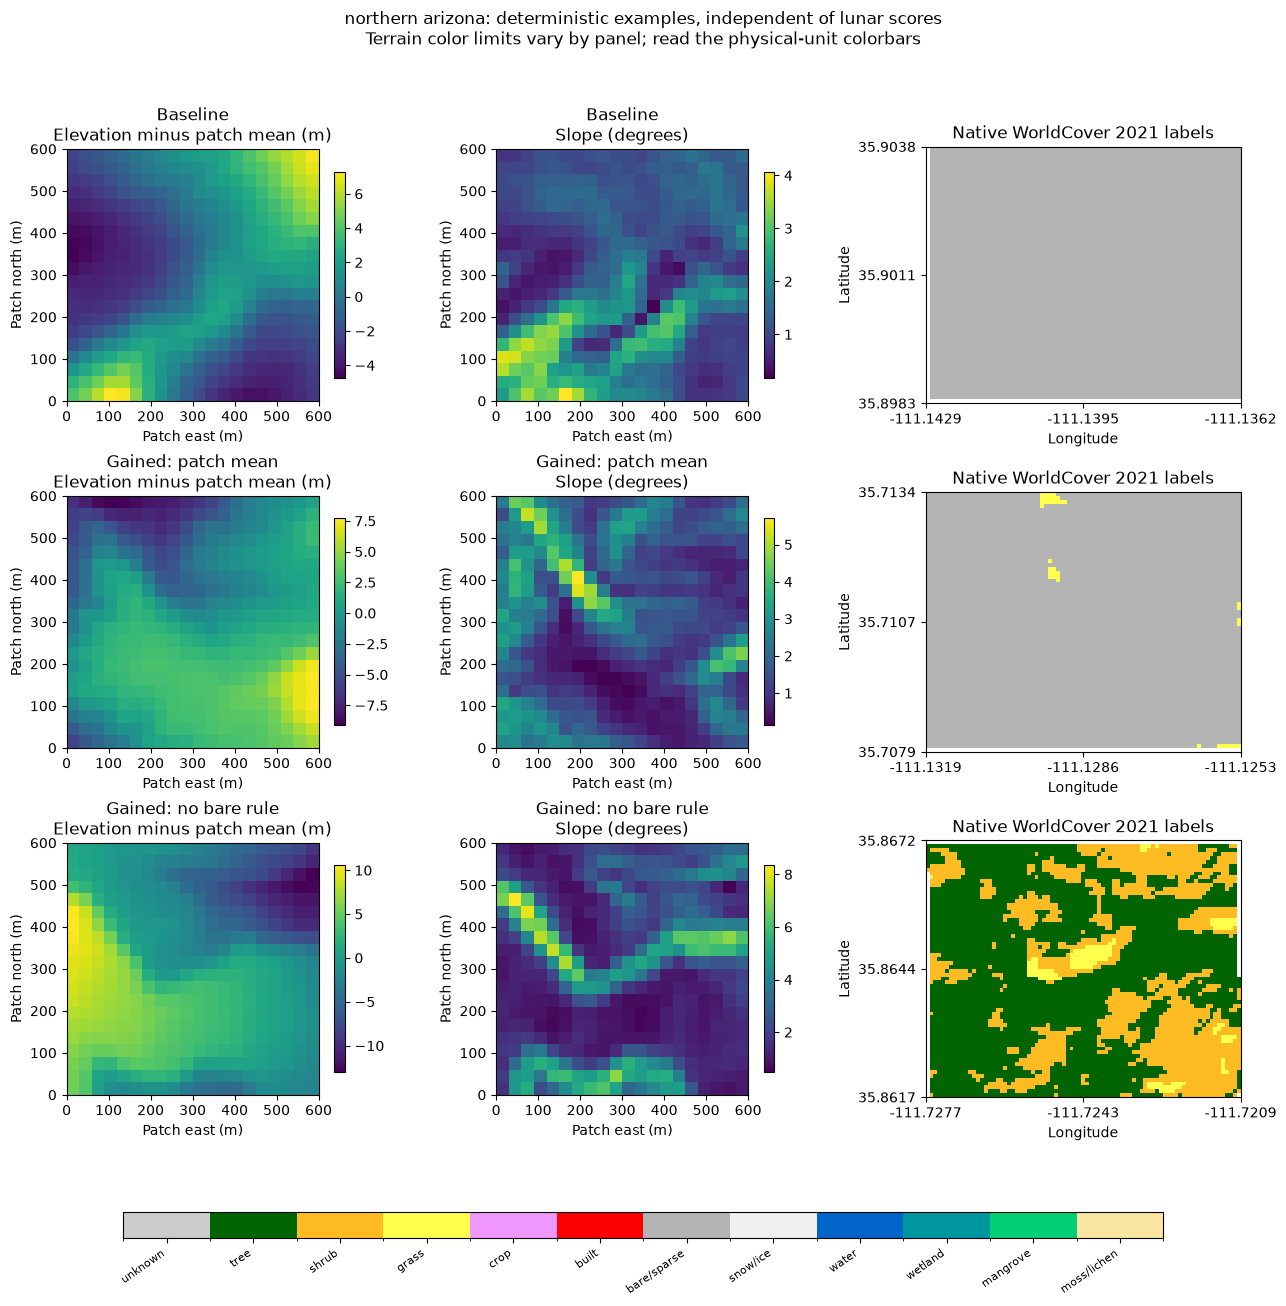

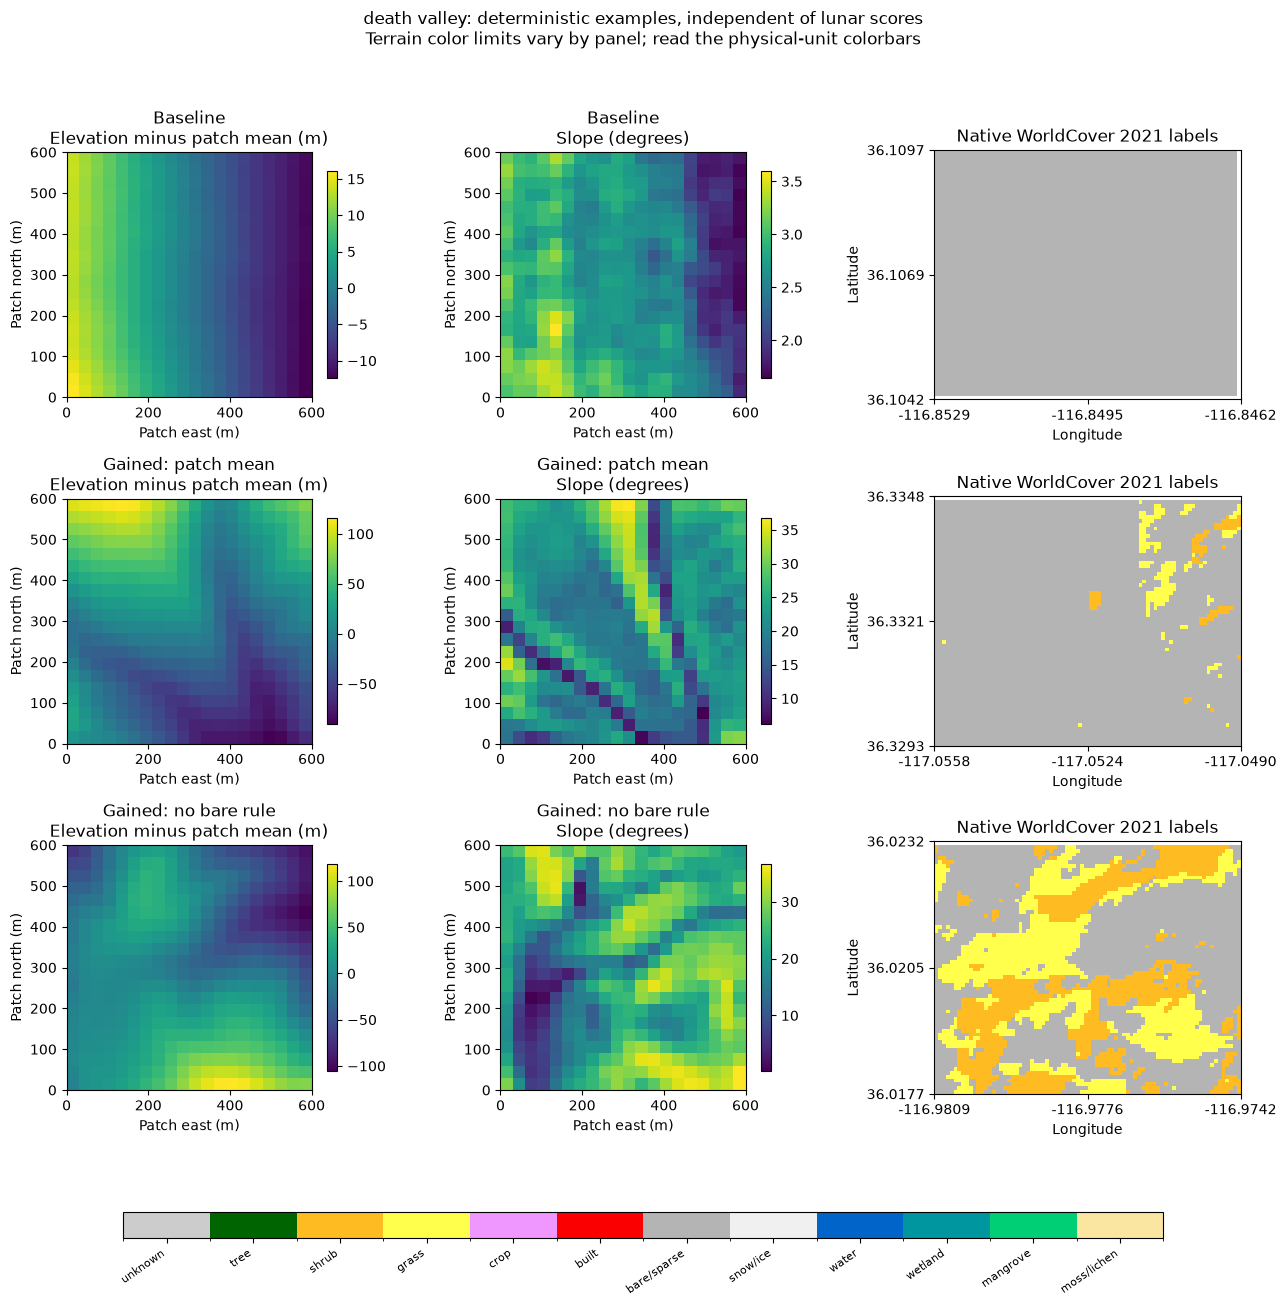

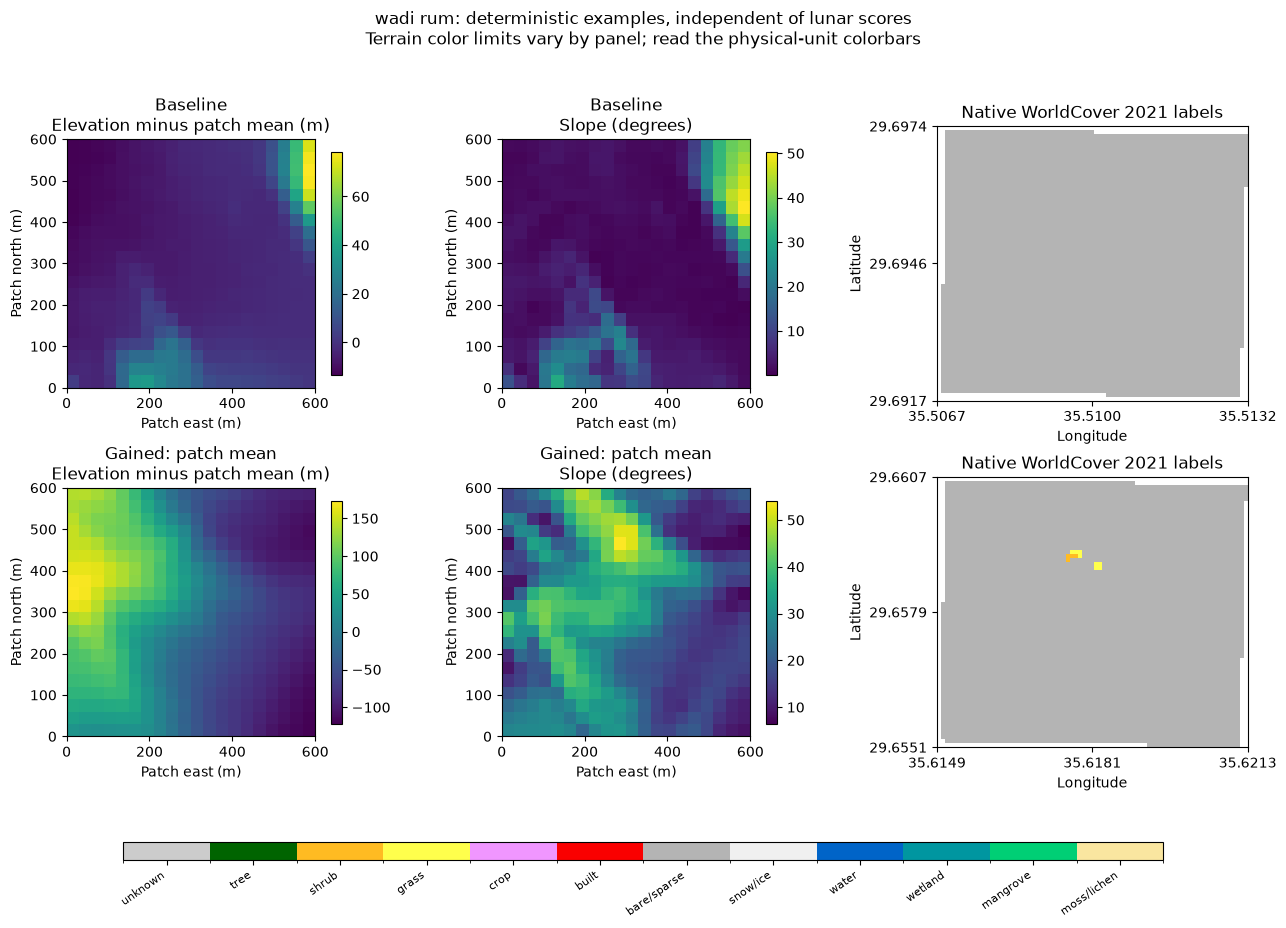

In [4]:
class_codes = np.array([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100])
class_labels = ['unknown', 'tree', 'shrub', 'grass', 'crop', 'built', 'bare/sparse', 'snow/ice', 'water', 'wetland', 'mangrove', 'moss/lichen']
class_colors = ['#cccccc', '#006400', '#ffbb22', '#ffff4c', '#f096ff', '#fa0000', '#b4b4b4', '#f0f0f0', '#0064c8', '#0096a0', '#00cf75', '#fae6a0']
gallery_rows = []
for site in SITES:
    group = patches.loc[(patches['region'] == site) & (patches['size_m'] == 600)].copy()
    choices = []
    for label, eligible in [('baseline', group['baseline']), ('gained_patch_mean', group['patch_mean_bare80'] & ~group['baseline']),
                            ('gained_no_bare', group['no_bare_requirement'] & ~group['patch_mean_bare80'])]:
        part = group.loc[eligible].copy()
        if part.empty:
            continue
        part['selection_distance'] = abs(part['slope_p90_deg'] - part['slope_p90_deg'].median())
        chosen = part.sort_values(['selection_distance', 'center_row', 'center_col']).iloc[0].to_dict()
        choices.append((label, chosen))
    assert choices
    class_cmap = ListedColormap(class_colors)
    class_norm = BoundaryNorm(np.arange(-.5, 12.5, 1), 12)
    fig, axes = plt.subplots(len(choices), 3, figsize=(13, 4 * len(choices) + 1), squeeze=False)
    for i, (label, chosen) in enumerate(choices):
        x, y = chosen['center_x_m'], chosen['center_y_m']
        bounds = (x - 300, y - 300, x + 300, y + 300)
        raw, selected, extent = read_native_classes(native_paths[site], bounds, grids[site]['crs_wkt'])
        assert np.isin(raw[selected], class_codes).all()
        for j, (channel, title) in enumerate([('elevation_m', 'Elevation minus patch mean (m)'), ('slope_deg', 'Slope (degrees)')]):
            with rasterio.open(check_input(folders[site] / f'{channel}.tif', expected, evidence)) as src:
                values = src.read(1, window=((int(chosen['row']), int(chosen['row']) + 20),
                                            (int(chosen['col']), int(chosen['col']) + 20)))
            if channel == 'elevation_m':
                values = values - values.mean()
            im = axes[i, j].imshow(values, extent=(0, 600, 0, 600), cmap='viridis')
            display_group = {'baseline': 'Baseline', 'gained_patch_mean': 'Gained: patch mean', 'gained_no_bare': 'Gained: no bare rule'}[label]
            axes[i, j].set(title=f'{display_group}\n{title}', xlabel='Patch east (m)', ylabel='Patch north (m)')
            fig.colorbar(im, ax=axes[i, j], shrink=.75)
        mapped = np.ma.array(np.searchsorted(class_codes, raw), mask=~selected)
        axes[i, 2].imshow(mapped, extent=extent, cmap=class_cmap,
                         norm=class_norm, interpolation='nearest')
        axes[i, 2].set(title='Native WorldCover 2021 labels', xlabel='Longitude', ylabel='Latitude')
        axes[i, 2].ticklabel_format(useOffset=False)
        axes[i, 2].set_xticks(np.linspace(extent[0], extent[1], 3),
                             labels=[f'{v:.4f}' for v in np.linspace(extent[0], extent[1], 3)])
        axes[i, 2].set_yticks(np.linspace(extent[2], extent[3], 3),
                             labels=[f'{v:.4f}' for v in np.linspace(extent[2], extent[3], 3)])
        counts = {str(code): int(np.count_nonzero(raw[selected] == code)) for code in class_codes}
        gallery_rows.append({'region': site, 'admission_group': label, 'center_id': chosen['center_id'],
                             'row': chosen['row'], 'col': chosen['col'], 'center_x_m': x, 'center_y_m': y,
                             'slope_p90_deg': chosen['slope_p90_deg'], 'bare_mean': chosen['bare_mean'],
                             'native_source': str(native_paths[site].relative_to(ROOT)), 'native_class_counts': json.dumps(counts, sort_keys=True)})
    fig.suptitle(site.replace('_', ' ') + ': deterministic examples, independent of lunar scores\nTerrain color limits vary by panel; read the physical-unit colorbars')
    fig.tight_layout(pad=1.2, h_pad=3, w_pad=3, rect=(0, .11, 1, .95))
    legend_ax = fig.add_axes((.1, .035, .8, .02))
    bar = fig.colorbar(ScalarMappable(norm=class_norm, cmap=class_cmap), cax=legend_ax,
                       orientation='horizontal', ticks=np.arange(12))
    bar.ax.set_xticklabels(class_labels, rotation=35, ha='right', fontsize=8)
    save_figure(fig, f'gallery_{site}')
pd.DataFrame(gallery_rows).to_csv(OUT / 'native_class_gallery.csv', index=False)

# Fixed-query candidate availability

Compute each query/candidate score once per size/site, then select each policy
and cohort using its explicit flags. No learned normalization or relevance labels.
Bands are unchanged from notebook 17. Record best score and in-band count per
Earth site; an empty candidate subset has zero matches and an infinite best score.
Original-three, four-site and five-site comparisons use identical lunar queries.

Scored 300 m


Scored 600 m


Scored 960 m


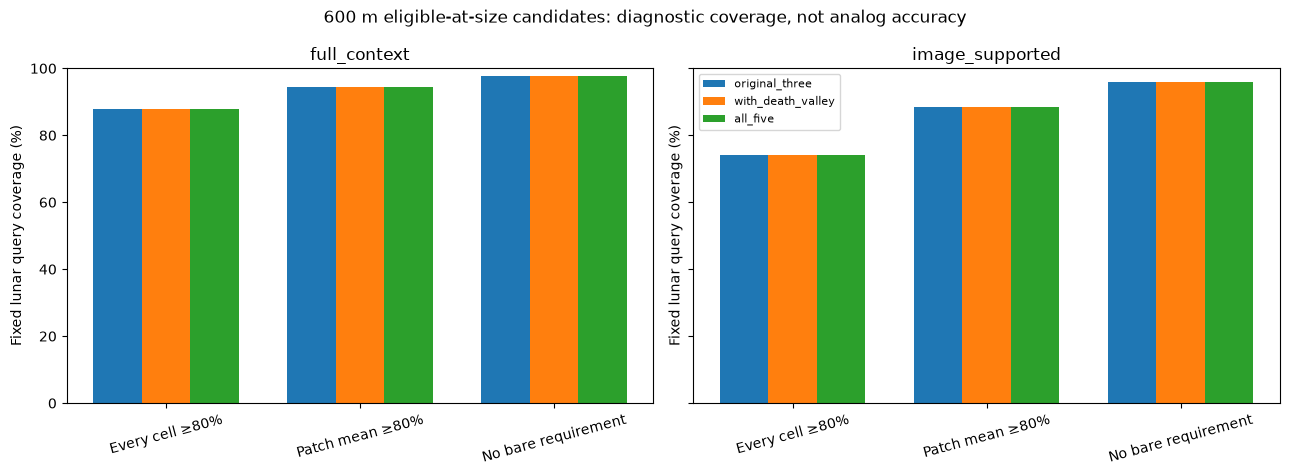

In [5]:
query_rows = []
for size in SIZES:
    groups = {site: patches.loc[(patches['region'] == site) & (patches['size_m'] == size)].reset_index(drop=True) for site in SITES}
    arrays = {site: group[FEATURES].to_numpy(dtype=float) for site, group in groups.items()}
    selections = {(site, policy, cohort): group[policy if cohort == 'eligible_at_size' else f'{policy}_common'].to_numpy(dtype=bool)
                  for site, group in groups.items() for policy in POLICIES for cohort in ['eligible_at_size', 'common_all_sizes']}
    for query in queries.loc[queries['size_m'] == size].to_dict('records'):
        values = np.array([query[f] for f in FEATURES], dtype=float)
        scores = {site: terrain_discrepancies(values, array) for site, array in arrays.items()}
        for policy in POLICIES:
            for cohort in ['eligible_at_size', 'common_all_sizes']:
                for scenario in SCENARIOS:
                    row = {'query_id': f'{query["center_id"]}:{size}', 'region': query['region'], 'population': query['population'],
                           'size_m': size, 'policy': policy, 'cohort': cohort, 'scenario': scenario}
                    for site in SITES:
                        chosen = scores[site][scenario][selections[site, policy, cohort]]
                        row[f'{site}_count'] = int(np.count_nonzero(chosen <= 1))
                        row[f'{site}_best'] = float(chosen.min()) if chosen.size else float('inf')
                    query_rows.append(row)
    print('Scored', size, 'm')
results = pd.DataFrame(query_rows)
results.to_csv(OUT / 'query_policy_results.csv.gz', index=False, compression='gzip')
summary_rows = []
for key, group in results.groupby(['size_m', 'policy', 'cohort', 'scenario', 'population']):
    assert isinstance(key, tuple)
    size, policy, cohort, scenario, population = key
    for region, part in [('ALL_QUERY_WEIGHTED', group), *list(group.groupby('region'))]:
        for pool, sites in [('original_three', SITES[:3]), ('with_death_valley', SITES[:4]), ('all_five', SITES)]:
            matched = (part[[f'{site}_count' for site in sites]].to_numpy() > 0).sum(axis=1)
            summary_rows.append({'size_m': size, 'policy': policy, 'cohort': cohort, 'scenario': scenario,
                                 'population': population, 'region': region, 'pool': pool, 'queries': len(part),
                                 'coverage_pct': 100 * np.mean(matched > 0), 'multisite_pct': 100 * np.mean(matched >= 2),
                                 'no_counterpart_pct': 100 * np.mean(matched == 0)})
coverage = pd.DataFrame(summary_rows)
coverage.to_csv(OUT / 'coverage.csv', index=False)
macro = coverage.loc[coverage['region'] != 'ALL_QUERY_WEIGHTED'].groupby(
    ['size_m', 'policy', 'cohort', 'scenario', 'population', 'pool'])[['coverage_pct', 'multisite_pct', 'no_counterpart_pct']].mean().reset_index()
macro.to_csv(OUT / 'coverage_region_macro.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, population in zip(axes, ['full_context', 'image_supported'], strict=True):
    frame = coverage.loc[(coverage['size_m'] == 600) & (coverage['scenario'] == 'baseline')
                         & (coverage['cohort'] == 'eligible_at_size') & (coverage['population'] == population)
                         & (coverage['region'] == 'ALL_QUERY_WEIGHTED')]
    for offset, pool in zip([-.25, 0, .25], ['original_three', 'with_death_valley', 'all_five'], strict=True):
        values = frame.loc[frame['pool'] == pool].set_index('policy').loc[POLICIES, 'coverage_pct']
        ax.bar(np.arange(3) + offset, values, .25, label=pool)
    ax.set(title=population, ylabel='Fixed lunar query coverage (%)', xticks=np.arange(3),
           xticklabels=['Every cell ≥80%', 'Patch mean ≥80%', 'No bare requirement'], ylim=(0, 100))
    ax.tick_params(axis='x', labelrotation=15)
axes[1].legend(fontsize=8)
fig.suptitle('600 m eligible-at-size candidates: diagnostic coverage, not analog accuracy')
fig.tight_layout()
save_figure(fig, '600m_policy_coverage')

# Findings and decision record

Per-site and per-query results support interpretation without selecting a
replacement screen from its matching percentage. Source labels, source accuracy,
morphology equivalence and practical simulation readiness are separate claims.

In [6]:
# Read the Markdown notes below for the standalone report export.
report_notebook = json.loads((ROOT / 'notebooks/exploration/22_cross_region_screening_eda.ipynb').read_text(encoding="utf-8"))
report_notes = {entry["metadata"]["report_section"]: "".join(entry["source"])
                for entry in report_notebook["cells"]
                if entry["cell_type"] == "markdown" and "report_section" in entry["metadata"]}
report = [
    *report_notes['narrative-869ca615-1'].split('\n'),
    'See the [predeclared comparison](../../../../notebooks/exploration/22_cross_region_screening_eda.ipynb) and [primary-source interpretation](../../../reference/screening-policy-20261029/SOURCE_INTERPRETATION.md). All policies require complete terrain and ≥0.99 land-cover support per cell, plus zero built/crop/water fractions per cell. They differ only in the bare/sparse requirement: ≥0.8 in every cell, ≥0.8 mean cell fraction in the patch, or no bare requirement.',
    *report_notes['narrative-869ca615-2'].split('\n'),
]
for row in inventory.loc[(inventory['size_m'] == 600) & (inventory['cohort'] == 'eligible_at_size')].to_dict('records'):
    report.append(f'| {row["region"]} | {row["policy"]} | {row["centers"]} | {row["slope_p90_median_deg"]:.2f} | '
                  f'{row["central_relief_median_m"]:.2f} | {row["p90_at_least_15deg_centers"]} |')
report += [
    *report_notes['narrative-869ca615-3'].split('\n'),
]
six = coverage.loc[(coverage['size_m'] == 600) & (coverage['population'] == 'image_supported') & (coverage['region'] == 'ALL_QUERY_WEIGHTED')]
for key, group in six.groupby(['cohort', 'policy', 'scenario']):
    assert isinstance(key, tuple)
    cohort, policy, scenario = key
    values = group.set_index('pool')
    report.append(f'| {cohort} | {policy} | {scenario} | {values.loc["original_three", "coverage_pct"]:.1f} | '
                  f'{values.loc["with_death_valley", "coverage_pct"]:.1f} | {values.loc["all_five", "coverage_pct"]:.1f} | '
                  f'{values.loc["all_five", "multisite_pct"]:.1f} |')
report += [
    *report_notes['narrative-869ca615-4'].split('\n'),
    '- [Center metrics and policy flags](center_screening_metrics.csv.gz), [site grids](site_grids.json), [inventory](policy_inventory.csv).',
    '- [Overlapping failures](overlapping_failure_counts.csv), [native gallery selections/counts](native_class_gallery.csv).',
    '- [Per-query site results](query_policy_results.csv.gz), [coverage](coverage.csv), [region macro coverage](coverage_region_macro.csv).',
    '- [Policy distributions](600m_policy_distributions.png), [coverage chart](600m_policy_coverage.png).',
]
for site in SITES:
    report.append(f'- {site}: [map](map_{site}.png), [native gallery](gallery_{site}.png).')
report += ['- [Provenance](provenance.json).', '']
(OUT / 'REPORT.md').write_text('\n'.join(report), encoding='utf-8')
provenance['inputs'] = evidence
provenance['outputs'] = {str(p.relative_to(OUT)): file_hash(p) for p in sorted(OUT.rglob('*')) if p.is_file() and p.name != 'provenance.json'}
provenance['status'] = 'publishing'
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
display(Markdown('\n'.join(report)))
print('Complete:', OUT)

# Cross-region screening comparison

Five development regions; fixed lunar queries; unchanged processed masks. Alternative policies are diagnostics, not validated analog eligibility or site readiness.

## Inputs and design

See the [predeclared comparison](../../../../notebooks/exploration/22_cross_region_screening_eda.ipynb) and [primary-source interpretation](../../../reference/screening-policy-20261029/SOURCE_INTERPRETATION.md). All policies require complete terrain and ≥0.99 land-cover support per cell, plus zero built/crop/water fractions per cell. They differ only in the bare/sparse requirement: ≥0.8 in every cell, ≥0.8 mean cell fraction in the patch, or no bare requirement.

Common-all-sizes membership is the intersection of each policy at 300/600/960 m; passing the largest patch alone is insufficient for the patch-mean policy. Lunar queries stay fixed to the previous common-960 cohort and retain both support views.

## 600 m eligible-at-size inventory

| Site | Policy | Centers | Median P90 slope (deg) | Median relief (m) | P90 ≥15° centers |
| --- | --- | ---: | ---: | ---: | ---: |
| atacama_san_pedro | baseline | 3675 | 4.95 | 27.81 | 762 |
| atacama_san_pedro | patch_mean_bare80 | 5041 | 6.77 | 36.36 | 1427 |
| atacama_san_pedro | no_bare_requirement | 5608 | 7.86 | 40.99 | 1737 |
| death_valley | baseline | 836 | 3.10 | 23.86 | 39 |
| death_valley | patch_mean_bare80 | 1578 | 8.73 | 47.56 | 656 |
| death_valley | no_bare_requirement | 2283 | 19.98 | 81.30 | 1279 |
| lanzarote | baseline | 55 | 4.93 | 24.93 | 1 |
| lanzarote | patch_mean_bare80 | 165 | 5.34 | 23.86 | 27 |
| lanzarote | no_bare_requirement | 273 | 6.28 | 29.87 | 90 |
| northern_arizona | baseline | 1086 | 2.66 | 11.69 | 48 |
| northern_arizona | patch_mean_bare80 | 2606 | 2.95 | 12.24 | 203 |
| northern_arizona | no_bare_requirement | 13582 | 4.58 | 17.70 | 1849 |
| wadi_rum | baseline | 1529 | 19.17 | 57.72 | 853 |
| wadi_rum | patch_mean_bare80 | 1859 | 24.38 | 75.54 | 1171 |
| wadi_rum | no_bare_requirement | 1859 | 24.38 | 75.54 | 1171 |

Complete-terrain/known-support denominators and overlapping failure reasons are exported separately. Policy memberships are nested at a fixed size; no data-quality gap is repaired by changing a land-cover requirement.

## 600 m strict-view query coverage

| Cohort | Policy | Score scenario | Original three (%) | With Death Valley (%) | All five (%) | All-five ≥2 sites (%) |
| --- | --- | --- | ---: | ---: | ---: | ---: |
| common_all_sizes | baseline | baseline | 61.8 | 61.8 | 61.8 | 1.1 |
| common_all_sizes | baseline | with_planarity | 33.1 | 33.2 | 33.2 | 0.8 |
| common_all_sizes | no_bare_requirement | baseline | 95.9 | 95.9 | 95.9 | 78.8 |
| common_all_sizes | no_bare_requirement | with_planarity | 74.3 | 74.5 | 74.5 | 44.8 |
| common_all_sizes | patch_mean_bare80 | baseline | 88.4 | 88.4 | 88.4 | 2.8 |
| common_all_sizes | patch_mean_bare80 | with_planarity | 57.0 | 57.3 | 57.3 | 2.0 |
| eligible_at_size | baseline | baseline | 74.3 | 74.3 | 74.3 | 2.2 |
| eligible_at_size | baseline | with_planarity | 50.9 | 51.0 | 51.0 | 1.7 |
| eligible_at_size | no_bare_requirement | baseline | 95.9 | 95.9 | 95.9 | 79.1 |
| eligible_at_size | no_bare_requirement | with_planarity | 74.3 | 74.5 | 74.5 | 45.1 |
| eligible_at_size | patch_mean_bare80 | baseline | 88.4 | 88.4 | 88.4 | 2.9 |
| eligible_at_size | patch_mean_bare80 | with_planarity | 57.0 | 57.3 | 57.3 | 2.0 |

Coverage gains from adding candidates or relaxing a nested policy are mechanically nonnegative. They do not measure retrieval accuracy or model generalization. Per-lunar-region results, region macro averages, both views and all scales remain in the tables.

## Source inspection and limits

The native-class galleries select one example per nonempty admission group/site by median P90 slope, independent of lunar scores. Counts use native pixel centers inside the projected patch, so they are not identical to area-aggregated 30 m fractions. WorldCover labels are not independent validation of current land cover, safety or terrain accuracy. Bare/sparse map fraction is not a measured vegetation percentage. The same DEM family across Earth does not remove spatially varying correction/error behavior.

## Decision

Keep the current baseline in processed outputs. Use the site-level selection effects and native source classes to decide what independent cover/source-quality evidence is needed before changing terrain eligibility. Separate morphology analysis from later Earth simulation readiness; do not choose a policy solely because it maximizes lunar-band coverage. All sites remain development data, and reserved-region morphology remains unopened.

## Artifacts

- [Center metrics and policy flags](center_screening_metrics.csv.gz), [site grids](site_grids.json), [inventory](policy_inventory.csv).
- [Overlapping failures](overlapping_failure_counts.csv), [native gallery selections/counts](native_class_gallery.csv).
- [Per-query site results](query_policy_results.csv.gz), [coverage](coverage.csv), [region macro coverage](coverage_region_macro.csv).
- [Policy distributions](600m_policy_distributions.png), [coverage chart](600m_policy_coverage.png).
- atacama_san_pedro: [map](map_atacama_san_pedro.png), [native gallery](gallery_atacama_san_pedro.png).
- lanzarote: [map](map_lanzarote.png), [native gallery](gallery_lanzarote.png).
- northern_arizona: [map](map_northern_arizona.png), [native gallery](gallery_northern_arizona.png).
- death_valley: [map](map_death_valley.png), [native gallery](gallery_death_valley.png).
- wadi_rum: [map](map_wadi_rum.png), [native gallery](gallery_wadi_rum.png).
- [Provenance](provenance.json).


Complete: .\data\processed\analysis\screening-eda-20261102T150311044638Z


# Cross-region screening comparison

Five development regions; fixed lunar queries; unchanged processed masks. Alternative policies are diagnostics, not validated analog eligibility or site readiness.

## Inputs and design



Common-all-sizes membership is the intersection of each policy at 300/600/960 m; passing the largest patch alone is insufficient for the patch-mean policy. Lunar queries stay fixed to the previous common-960 cohort and retain both support views.

## 600 m eligible-at-size inventory

| Site | Policy | Centers | Median P90 slope (deg) | Median relief (m) | P90 ≥15° centers |
| --- | --- | ---: | ---: | ---: | ---: |


Complete-terrain/known-support denominators and overlapping failure reasons are exported separately. Policy memberships are nested at a fixed size; no data-quality gap is repaired by changing a land-cover requirement.

## 600 m strict-view query coverage

| Cohort | Policy | Score scenario | Original three (%) | With Death Valley (%) | All five (%) | All-five ≥2 sites (%) |
| --- | --- | --- | ---: | ---: | ---: | ---: |


Coverage gains from adding candidates or relaxing a nested policy are mechanically nonnegative. They do not measure retrieval accuracy or model generalization. Per-lunar-region results, region macro averages, both views and all scales remain in the tables.

## Source inspection and limits

The native-class galleries select one example per nonempty admission group/site by median P90 slope, independent of lunar scores. Counts use native pixel centers inside the projected patch, so they are not identical to area-aggregated 30 m fractions. WorldCover labels are not independent validation of current land cover, safety or terrain accuracy. Bare/sparse map fraction is not a measured vegetation percentage. The same DEM family across Earth does not remove spatially varying correction/error behavior.

## Decision

Keep the current baseline in processed outputs. Use the site-level selection effects and native source classes to decide what independent cover/source-quality evidence is needed before changing terrain eligibility. Separate morphology analysis from later Earth simulation readiness; do not choose a policy solely because it maximizes lunar-band coverage. All sites remain development data, and reserved-region morphology remains unopened.

## Artifacts


## Save reusable data and disposable reports
Run this final cell after the displays. Later notebooks read only the data directory; reports can be deleted and regenerated.

In [7]:
import sys

sys.path.insert(0, str(ROOT))
from notebooks.shared.analysis_artifacts import publish_analysis

REPORT_OUT = publish_analysis(ROOT, OUT, manifest_name="provenance.json")
print("Reusable data:", OUT)
print("Disposable reports:", REPORT_OUT)

Reusable data: .\data\processed\analysis\screening-eda-20261102T150311044638Z
Disposable reports: .\reports\analysis\screening-eda-20261102T150311044638Z
